# Studio 4 -- Complex Root Finding and Fractals
## Put your group number and the full names of you and your groupmates here:
### Group: #
- 1 -- 
- 2 -- 
- 3 --



In [1]:
## run this cell first to import all the necessary tools
import numpy as np
from matplotlib import pyplot as plt
from scipy.optimize import newton

# Problem 1

## Complex Numbers in NumPy/Python

Unlike many programming languages, Python has a built-in complex number type.  I can express the complex number $z = 2+3i$ as:

In [2]:
z = 2 + 3j

There are technically two ways I can manipulate complex numbers in Python: I can either import the `cmath` package (the complex equivalent of the `math` package that also comes with Python), or I can use NumPy.  Let's stick with NumPy, since it contains all the same functions, and they work on single numbers and NumPy arrays

Most NumPy functions, like `sin`, `cos`, `log`, `exp`, etc. that work for real numbers work for complex numbers as well.  There are also specialized functions for complex numbers:

- `np.real` -- Returns the real part of a complex number 
- `np.imag` -- Returns the imaginary part of a complex number 
- `np.abs` -- Returns the modulus (length) of a complex number 
- `np.angle` -- Returns the argument (angle in polar coordinates) of a complex number 

## Part A) 

Take three complex numbers:

$$ z_1 = 2i,~~~~z_2 = -0.2 + 4i,~~~~z_3=6$$

Create a NumPy array containing all three numbers, and use the NumPy functions to calculate the real and imaginary parts, the modulus, and argument, of the full array

In [ ]:
z_array = ## Put answer here

In [ ]:
## Put answer here

## Part B) 

Numerically "prove" Problem 1(f) from the Homework

$$z^n = r^n(\cos n\phi + i \sin n\phi)$$

by calculating both sides and asking whether the two arrays you get are equal.  Pick a random $n$ (other than 0) to test this against.

**HINT**: Try both printing out the left and right hand sides **and** testing for equality by using `==`.  

In [ ]:
## Put answer here

What causes this disagreement?  **Put your answer here**

## Part C) 

If I want to evaluate a function for many complex numbers, I can't use `np.linspace` or `np.arange`, I need some way to create a **grid of complex numbers**.

Create a 200x200 grid of complex numbers.  The real part should go from $-10$ to $10$, and the imaginary part from $-10i$ to $10i$

**HINT**: I've given you below the code to create a blank 200x200 grid of zeros that you can fill in with complex numbers.  For NumPy arrays, a 2D array is accesed by `array[row][column]`.  For our purposes, let's have the rows of our matrix be the imaginary axis and the columns be the real part (e.g. if `array[row][column]=0.5+0.5i`, then `array[row+1][column] = 0.5+(0.5+0.1)i`, and so on)

In [4]:
real_part = np.linspace(-10,10,200)
imag_part = np.linspace(-10,10,200)

grid = np.zeros(shape=(200,200),dtype=np.complex128)

for i in range(200):
    for j in range(200):
        grid[i][j] = real_part[i] + 1j*imag_part[j]

Save this grid!  We're going to use it below

# Problem 2

## Root Finding for Complex Functions

In HW04, you implemented a 2D Newton-Raphson algorithm using a Jacobian inverse.  But you may have realized that, for a complex function, we don't actually need to compute the derivatives separately; we can also just calculate the derivative of a function 

$$f(z) = z^3 - 1$$

as 

$$f'(z) = 3z^2$$

This means for complex functions, if we have a programming language that can handle complex numbers (like Python), we can just use 1D Newton-Raphson

## Part A)

Just as we did in the last studio, use SciPy's Newton function to compute the roots of the above function, by coding up $$f(z)$$ and it's derivative $$f'(z)$$But this time, use the 1D complex function above and it's derivative.  Have the `newton` function calculate the root of **every** point in your grid.  Like most NumPy/SciPy functions, this can be done in a single line with no `for` loops.

In [6]:
from scipy.optimize import newton

def cfunc(z):
    '''
    The complex function f(z) = z^3 - 1
        
    PARAMETERS:
        z - Complex Number
    
    RETURN VALUE:
        Value of Function
    '''
    ## Put your answer here
    return z**3 - 1

def dcfunc(z):
    '''
    The derivatize of the complex function f(z) = z^3 - 1
        
    PARAMETERS:
        z - Complex Number
    
    RETURN VALUE:
        Value of derivative at z
    '''
    ## Put your answer here
    return 3*z**2

roots = newton(cfunc,grid,fprime=dcfunc,maxiter=200)

## Part B)

As you did in the Homework, each of the points should find a different root, but there should only be handful of unique roots for the given function.  Using the `np.unique` function, how many roots does your grid produce?  Looking at the output, how many **actually** unique roots are there.

**Note:** You may want to increase the max number of iterations to 200

In [7]:
np.unique(roots)

array([-0.5-8.66025404e-01j, -0.5-8.66025404e-01j, -0.5+8.66025404e-01j,
       -0.5+8.66025404e-01j,  1. -1.96530036e-21j,  1. +0.00000000e+00j,
        1. +1.96530359e-21j])

**Put your text answer here**

## Part C)

Let's plot in the complex plane what root each of your input grid points actually converges to.  **Using the provided function**, convert your grid of roots into unique colors, and plot them using the `plt.imshow` function

In [9]:
def root_to_color(grid_of_roots,unique_roots):
    '''
    Function to map each root from grid_of_roots to a color, 
    based on which root in unique_roots it's closest to.
        
    PARAMETERS:
        grid_of_roots - 2D np.array of all the roots of your grid
        unique_roots - 1D np.array or Python list of the unique roots you found above
    
    RETURN VALUE:
        colors - 2D np.array where each root that matches a root in unique_root is assigned a color
    '''
    ## Put your answer here

    colors = np.zeros_like(grid_of_roots)
    
    for idx,unique_root in enumerate(unique_roots):
        this_root = idx * np.isclose(unique_root,grid_of_roots).astype(int)
        colors += this_root
        
    return np.real_if_close(colors)

unique_roots = [-0.5-8.66025404e-01j,-0.5+8.66025404e-01j,1]

colors = root_to_color(roots,unique_roots)

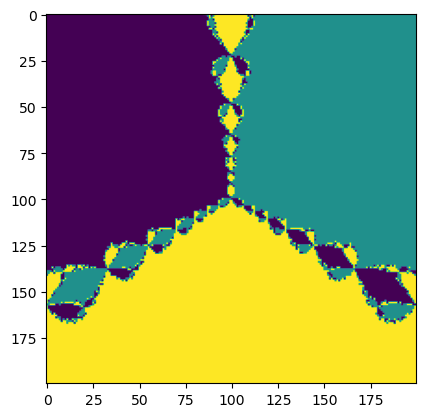

In [10]:
plt.imshow(colors)

Just based on the names of the function, what do you think the above function is actually doing?

**Put your text answer here**